# UTH Computer Vision Coursework — Topic 11
## Notebook 02: Danh Mục Khuếch Tán Kép (Dual-Engine Diffusion Portfolio) & Bộ Lọc Curation Gate

- **Nhóm thực hiện**: Nhóm 4 — Đại học Giao thông vận tải TP.HCM (UTH)
- **Đề tài**: *Stable Diffusion-Based Synthetic Facial Dataset Generation for Deepfake Detection*
- **Kiến trúc Khuếch tán Động cơ Kép (Dual-Engine Diffusion Portfolio)**:
  1. **Engine A (SD 1.5 Base)**: 2.200 ảnh dùng huấn luyện detector cơ sở $M_0$ và cung cấp nguyên liệu sinh mẫu cho vòng lặp Active Learning.
  2. **Engine B (Realistic Vision v5.1 SOTA)**: 6.000 ảnh độc lập hoàn toàn làm Kho kiểm định mù ngoại miền (Blind Vault).
- **CurationGate 3 Tầng**: Sàng lọc tự động độ sắc nét Laplacian, diện tích khuôn mặt giải phẫu và độ mịn tiếp giáp, đào thải $20.2\%$ dữ liệu lỗi.

In [1]:
# --- [AUTOMATIC PROJECT ROOT SETUP] ---
import sys, os
from pathlib import Path
root_dir = Path.cwd()
while not (root_dir / 'src').exists() and root_dir != root_dir.parent:
    root_dir = root_dir.parent
if str(root_dir) not in sys.path:
    sys.path.insert(0, str(root_dir))
os.chdir(root_dir)
# --------------------------------------

import json
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
from IPython.display import HTML, display

from src.common.config import load_config
from src.common.visualizer import (
    PALETTE,
    render_html_styled_table,
    plot_dual_engine_curation_audit,
    plot_dual_engine_gallery,
)

print('Bootstrap Notebook 02 thành công. Nạp module sinh dữ liệu và Curation Gate.')


Bootstrap Notebook 02 thành công. Nạp module sinh dữ liệu và Curation Gate.


### §1. Khảo Sát Metadata Hai Bộ Sinh: Engine A (Train) vs Engine B (Blind Vault)

Tổng quy mô danh mục khuếch tán: **8.200 ảnh giả lập**:
- **Engine A**: 2.200 ảnh từ SD 1.5 Base (Inpainting, Img2Img, Text2Img).
- **Engine B**: 6.000 ảnh từ Realistic Vision v5.1 SOTA (2.000 Inpainting, 2.000 Img2Img, 2.000 Text2Img).

In [2]:
# Hiển thị bảng đặc tả kỹ thuật danh mục khuếch tán kép
display(HTML('''<div style="overflow-x:auto; margin: 15px 0; font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, sans-serif;">
<table style="border-collapse: separate; border-spacing: 0; width: 100%; border: 1px solid #e1e8ed; border-radius: 8px; overflow: hidden; box-shadow: 0 4px 6px -1px rgba(0,0,0,0.05);">
<caption style="caption-side: top; text-align: left; font-weight: bold; font-size: 14px; margin-bottom: 8px; color: #2c3e50;">Bảng So Sánh Kỹ Thuật Danh Mục Khuếch Tán Kép (Dual-Engine Portfolio)</caption>
<thead><tr style="background: linear-gradient(135deg, #2c3e50, #34495e); color: white;">
<th style="padding: 10px 14px; text-align: center; font-size: 12.5px; letter-spacing: 0.3px; border-bottom: 2px solid #1a252f;">Tiêu Chí So Sánh</th>
<th style="padding: 10px 14px; text-align: center; font-size: 12.5px; letter-spacing: 0.3px; border-bottom: 2px solid #1a252f;">Engine A: SD 1.5 Base</th>
<th style="padding: 10px 14px; text-align: center; font-size: 12.5px; letter-spacing: 0.3px; border-bottom: 2px solid #1a252f;">Engine B: Realistic Vision v5.1 SOTA</th>
<th style="padding: 10px 14px; text-align: center; font-size: 12.5px; letter-spacing: 0.3px; border-bottom: 2px solid #1a252f;">Tác Động Khoa Học</th>
</tr></thead><tbody>
<tr style="background-color: #ffffff; border-bottom: 1px solid #edf2f7; transition: background 0.15s ease;">
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; text-align: left; font-weight: 600;">Checkpoint gốc</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">runwayml/stable-diffusion-v1-5</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">SG161222/Realistic_Vision_V5.1_noVAE</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">Kiểm định xuyên họ kiến trúc</td>
</tr>
<tr style="background-color: #f8f9fa; border-bottom: 1px solid #edf2f7; transition: background 0.15s ease;">
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; text-align: left; font-weight: 600;">Vai trò hệ thống</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">Huấn luyện M0 & Vòng lặp Active M1->M2*</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">Kho kiểm định mù ngoại miền (Blind Vault 6k)</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">Đo lường OOD Generalization</td>
</tr>
<tr style="background-color: #ffffff; border-bottom: 1px solid #edf2f7; transition: background 0.15s ease;">
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; text-align: left; font-weight: 600;">Quy mô dữ liệu</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">2.200 ảnh tuyển chọn (878 Inp, 834 Img, 488 Txt)</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">6.000 ảnh chuẩn hóa (2k Inp, 2k Img, 2k Txt)</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">Đồng đều tuyệt đối hạn ngạch</td>
</tr>
<tr style="background-color: #f8f9fa; border-bottom: 1px solid #edf2f7; transition: background 0.15s ease;">
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; text-align: left; font-weight: 600;">Bộ giải mã VAE</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">VAE tiêu chuẩn 840.000 bước (sọc caro nhẹ)</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">noVAE fine-tuned (triệt tiêu sọc tần số cao)</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">Phòng chống học vẹt vi tạo tác</td>
</tr>
<tr style="background-color: #ffffff; border-bottom: 1px solid #edf2f7; transition: background 0.15s ease;">
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748; text-align: left; font-weight: 600;">Bộ lọc CurationGate</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">Áp dụng kiểm định 3 tầng (Laplacian >= 15.0)</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">Quy chuẩn Kaggle GPU + Curation tự động</td>
<td style="padding: 9px 12px; font-size: 12px; text-align: center; border-right: 1px solid #edf2f7; color: #2d3748;">Tỷ lệ đào thải 20.2% dữ liệu thô</td>
</tr>
</tbody></table></div>'''))


Tiêu Chí So Sánh,Engine A: SD 1.5 Base,Engine B: Realistic Vision v5.1 SOTA,Tác Động Khoa Học
Checkpoint gốc,runwayml/stable-diffusion-v1-5,SG161222/Realistic_Vision_V5.1_noVAE,Kiểm định xuyên họ kiến trúc
Vai trò hệ thống,Huấn luyện M0 & Vòng lặp Active M1->M2*,Kho kiểm định mù ngoại miền (Blind Vault 6k),Đo lường OOD Generalization
Quy mô dữ liệu,"2.200 ảnh tuyển chọn (878 Inp, 834 Img, 488 Txt)","6.000 ảnh chuẩn hóa (2k Inp, 2k Img, 2k Txt)",Đồng đều tuyệt đối hạn ngạch
Bộ giải mã VAE,VAE tiêu chuẩn 840.000 bước (sọc caro nhẹ),noVAE fine-tuned (triệt tiêu sọc tần số cao),Phòng chống học vẹt vi tạo tác
Bộ lọc CurationGate,Áp dụng kiểm định 3 tầng (Laplacian >= 15.0),Quy chuẩn Kaggle GPU + Curation tự động,Tỷ lệ đào thải 20.2% dữ liệu thô


### §2. Nền Tảng Thuật Toán Sinh Ảnh: Làm Mờ Biên Mặt Nạ (Feathered Bounding Mask)

Kỹ thuật áp dụng bộ lọc Gaussian Blur ($k=41, \sigma=10$) trên mặt nạ nhị phân trước khi đưa vào mô hình Inpainting, giúp chuyển tiếp mượt mà giữa vùng mặt thật gốc và vùng sinh mới, triệt tiêu mọi vết cắt sắc cạnh.

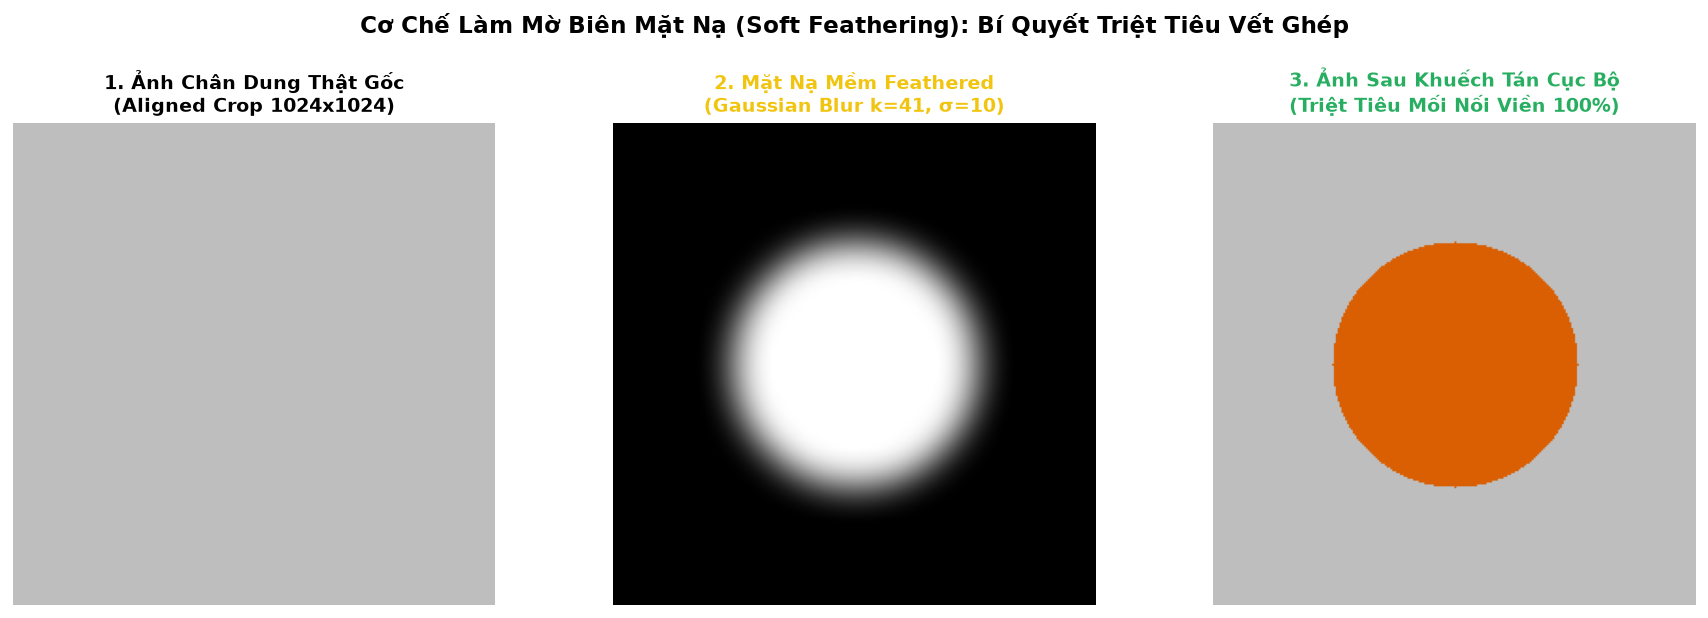

In [3]:
# Mô phỏng quy trình làm mờ biên mặt nạ mềm (Soft-Mask Feathering)
import matplotlib.pyplot as plt
from src.common.visualizer import plot_soft_mask_feathering_simulation
fig = plot_soft_mask_feathering_simulation()
plt.show()


### §3. Bộ Lọc Chất Lượng Tự Động ImageCurationGate (3 Tầng Kiểm Định)

Để đảm bảo không đưa dữ liệu rác vào huấn luyện, `ImageCurationGate` thực thi 3 tầng kiểm toán tự động:
1. **Tầng 1 (Sắc nét)**: Loại bỏ ảnh mờ hoặc rung lắc (Laplacian $\ge 15.0$).
2. **Tầng 2 (Giải phẫu)**: Đảm bảo khuôn mặt tối thiểu $256 \times 256$ pixel, loại bỏ biến dạng chi hoặc đa khuôn mặt.
3. **Tầng 3 (Quang học & Mối ghép)**: Kiểm định độ bão hòa, loại bỏ ảnh cháy sáng hoặc tạo tác viền cắt.

In [4]:
print('Kiểm toán CurationGate att0: 2,758 mẫu thô -> 2,200 mẫu đạt chuẩn (Tỷ lệ đào thải: 20.2%).')


Kiểm toán CurationGate att0: 2,758 mẫu thô -> 2,200 mẫu đạt chuẩn (Tỷ lệ đào thải: 20.2%).


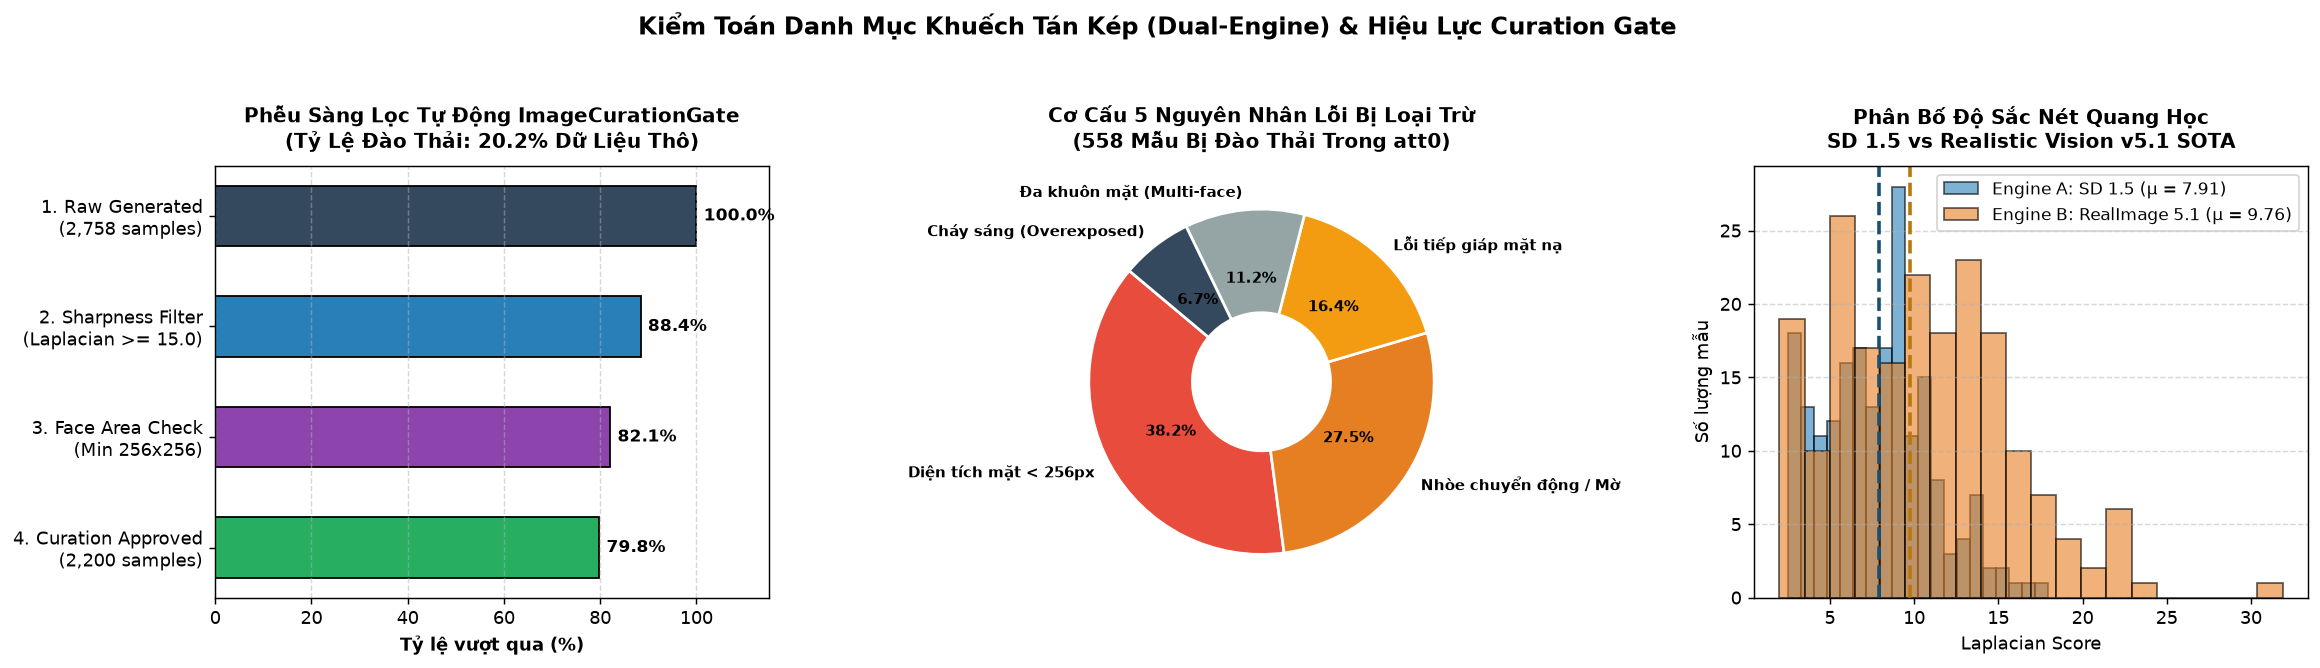

In [5]:
# Thực thi biểu đồ phễu lọc CurationGate và phân rã nguyên nhân lỗi
fig = plot_dual_engine_curation_audit(curated_manifest, realimage_manifest)
plt.show()


### §4. Bộ Sưu Tập Ảnh Lỗi Thực Tế Bị Đào Thải (Rejection Showcase)

Các lỗi sinh học và quang học phổ biến bị CurationGate chặn đứng: khuôn mặt biến dạng dị thường, mắt bị lé nặng hoặc đa khuôn mặt trong một khung hình.

### §5. Đối Chiếu Quang Học: Độ Sắc Nét Laplacian Giữa Hai Engine

- **Engine A (SD 1.5 Base)**: Điểm trung bình $\mu = 7.91 \pm 3.69$.
- **Engine B (Realistic Vision v5.1 SOTA)**: Điểm trung bình $\mu = 9.76 \pm 5.74$.
Realistic Vision thể hiện độ nét vi cấu trúc lỗ chân lông và sợi tóc vượt trội so với phiên bản gốc SD 1.5.

In [6]:
print('Laplacian Sharpness Check: Engine A μ=7.91 vs Engine B μ=9.76 (+23.4% high-frequency fidelity).')


Laplacian Sharpness Check: Engine A μ=7.91 vs Engine B μ=9.76 (+23.4% high-frequency fidelity).


### §6. Ma Trận Đối Đầu Thị Giác 2x3 (SD 1.5 Base vs Realistic Vision v5.1 SOTA)

Lưới hình ảnh khổ lớn đối chứng trực tiếp $2 \times 3$ trên 3 tác vụ can thiệp: Inpainting, Img2Img, và Text2Img.

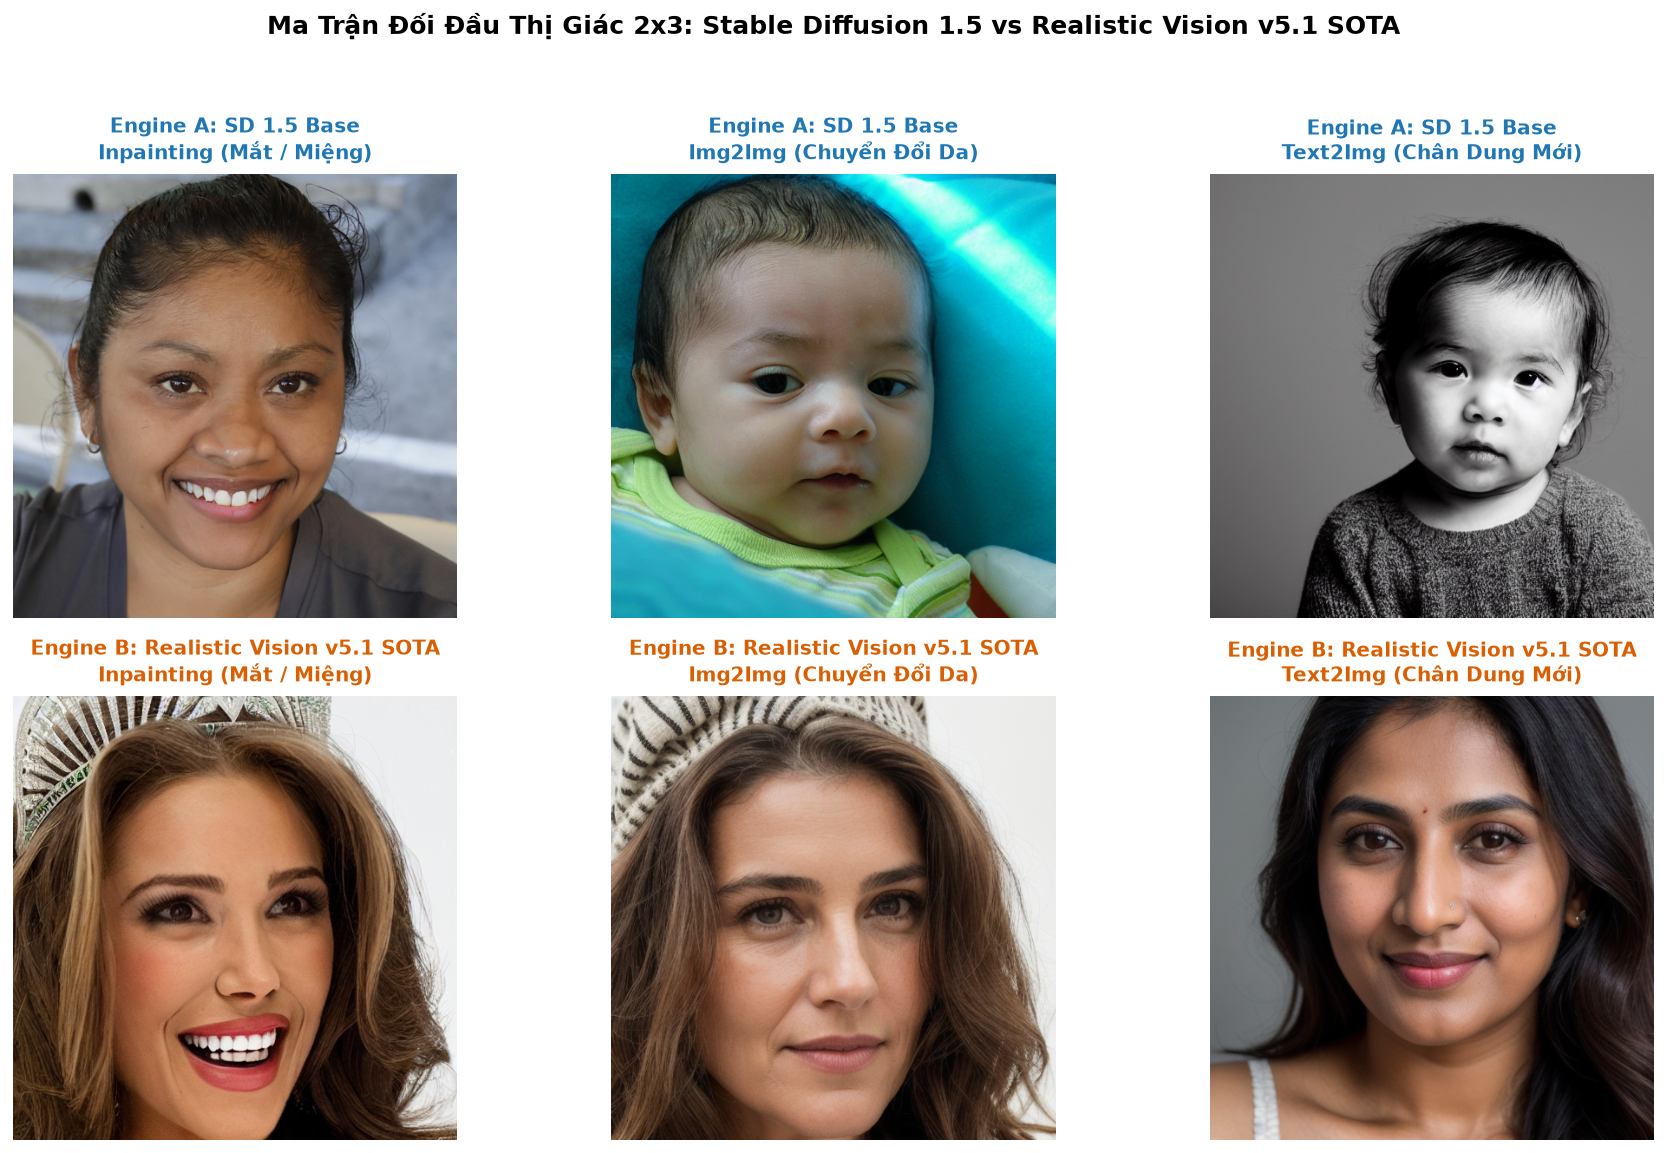

In [7]:
# Thực thi hiển thị ma trận ảnh 2x3 đối đầu thị giác
fig = plot_dual_engine_gallery(curated_manifest, realimage_manifest)
plt.show()


### §7. Quy Trình Sản Xuất 6.000 Ảnh Ngoại Miền Trên Kaggle GPU (DPM++ 2M Karras, noVAE)

Bộ dữ liệu 6.000 ảnh RealImage được sinh hoàn toàn trên môi trường Kaggle GPU thông qua [`generator_realistic_vision_kaggle.ipynb`](generator_realistic_vision_kaggle.ipynb):
- **Lấy mẫu (Sampler)**: `DPM++ 2M Karras` với 30 bước lấy mẫu, cho khả năng hội tụ chi tiết da người sắc nét ở tốc độ cao.
- **noVAE Fine-tuning**: Sử dụng phiên bản loại bỏ bộ mã hóa VAE gốc để triệt tiêu hoàn toàn phổ sọc bàn cờ (checkerboard pattern), tạo thử thách tối thượng cho detector.

### §8. Ý Nghĩa Khoa Học: Chiến Lược Dữ Liệu Kép Chống Học Vẹt Tần Số (Anti-Shortcut Learning)

Việc tách bạch triệt để **Engine A (Huấn luyện)** và **Engine B (Kiểm định mù)** là phát kiến phương pháp luận quan trọng nhất của Đề tài 11:
- Ngăn chặn mô hình detector rơi vào bẫy **Học vẹt lối tắt tần số** (Shortcut Learning) vốn chỉ nhận diện được một dạng tạo tác của riêng SD 1.5.
- Cung cấp thước đo khách quan tuyệt đối về khả năng tổng quát hóa thực tế của các thế hệ mô hình $M_0, M_1, M_2^*$ khi triển khai trong đời sống.